# AI5707 — Assignment 8
## Pattern Recognition and Machine Learning

**Team 16**

This notebook implements the assignment experiment with handwritten algorithms. The shared module contains the LCG random generator, polar Box–Muller Gaussian generator, and from-scratch models. No scikit-learn model implementation is used.

## 1. Imports and common implementations

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "assignment8_common.py").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from assignment8_common import *
print("Dataset directory:", DATA)
print("Random generator seed:", seed)

Dataset directory: D:\Storage\OneDrive\Desktop\Lab 8\DATASETS
Random generator seed: 42


## Combined classifier comparison
Run notebooks 01–04 first. This notebook reads the experiment CSV outputs and presents a combined view. DTW is shown separately because it is the sequence-specific method.

,Features,GMM,LDA,KNN,SVM,Dataset
0,Original,1.00000,0.96650,0.99675,0.99500,mnist_labelled_file_results
1,PCA-2,0.91650,0.90725,0.91050,0.91175,mnist_labelled_file_results
2,PCA-4,0.93950,0.92000,0.93025,0.93350,mnist_labelled_file_results
3,PCA-8,0.98075,0.93675,0.97225,0.96575,mnist_labelled_file_results
4,PCA-12,0.99675,0.95600,0.99225,0.99075,mnist_labelled_file_results
5,Original,0.55400,0.53200,0.47800,0.56200,image_results
6,PCA-2,0.34600,0.30400,0.33600,0.30000,image_results
7,PCA-4,0.46600,0.36000,0.41000,0.43200,image_results
8,PCA-8,0.52000,0.49400,0.48200,0.52400,image_results
9,PCA-12,0.58200,0.49800,0.49800,0.55200,image_results


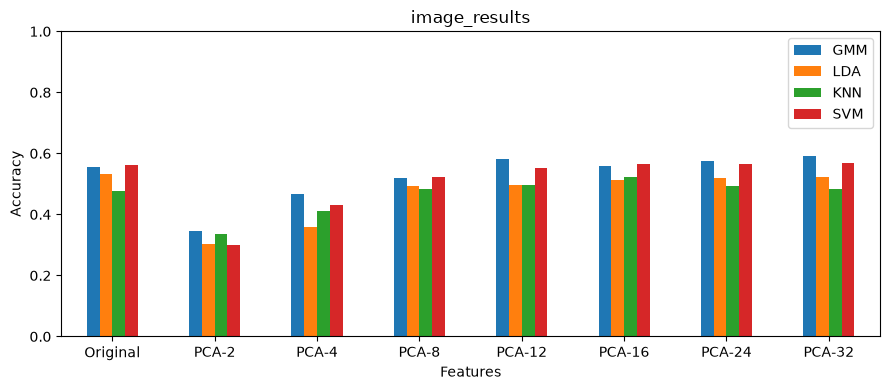

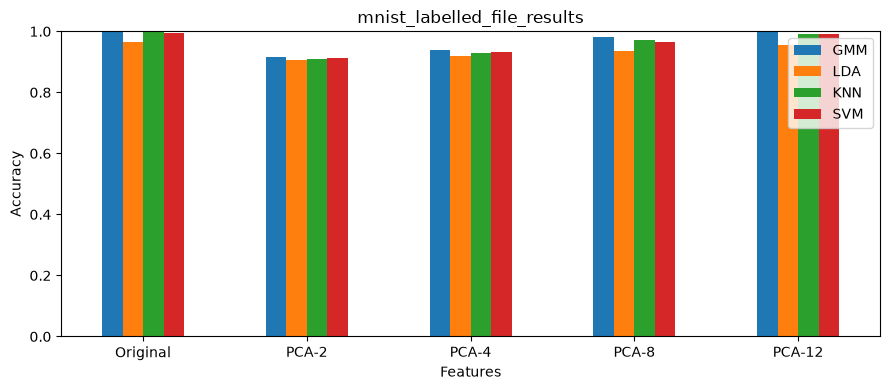

TI Digits DTW accuracy: 0.9


In [2]:
files=[OUT/"synthetic_results.csv",OUT/"mnist_labelled_file_results.csv",OUT/"image_results.csv"]
frames=[]
for f in files:
    if f.exists():
        df=pd.read_csv(f); df["Dataset"]=f.stem; frames.append(df)
if frames:
    combined=pd.concat(frames,ignore_index=True); display(combined)
    combined.to_csv(OUT/"accuracy_comparison_manual.csv",index=False)
    for dataset,df in combined.groupby("Dataset"):
        ax=df.set_index("Features")[["GMM","LDA","KNN","SVM"]].plot(kind="bar",ylim=(0,1),figsize=(9,4),title=dataset)
        ax.set_ylabel("Accuracy"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
else:
    print("Run experiment notebooks 01, 02, and 03 first.")
dtw_file=OUT/"ti_digits_dtw_predictions.csv"
if dtw_file.exists():
    d=pd.read_csv(dtw_file); print("TI Digits DTW accuracy:",accuracy_score(d.true,d.predicted))